In [232]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
data = pd.read_csv("")
data = data
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [234]:
mean = np.nanmean(data['total_bedrooms'].values)

for i in range(0,len(data['total_bedrooms'])):
    if  np.isnan(data['total_bedrooms'][i]) == True :
        data.loc[i, "total_bedrooms"] = mean


In [235]:
DataTranspose = data.transpose()

Data Preparation

In [236]:
DataTranspose2 = DataTranspose.head(9)

X = []
Y = []
for i in DataTranspose2:
    X.append(np.array(DataTranspose2[i][:8]))
    Y.append(np.array(DataTranspose2[i][8]))


#Scalling
def ScalingStuff(List:list):
    Mean = np.mean(List)
    
    #Strardard deviation
    SD = 0
    for v in List:
        SD += (v - Mean)**2 / (len(List))
    SD = SD**(1/2)



    NewList = []
    for v in List:
        NewList.append((v - Mean)/ SD)

    return NewList


for i in range(0,len(X[0])):
    List = [x[i] for x in X]
    List = ScalingStuff(List)
    for i2 in range(0,len(List)):
        X[i2][i] = List[i2]

Y = ScalingStuff(Y)




C:\Users\hd767\AppData\Local\Temp\ipykernel_26896\3685894839.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Y.append(np.array(DataTranspose2[i][8]))


In [237]:

#FOR THE LIBARY MODEL

import sklearn as skl
from sklearn.model_selection import train_test_split
X_Train,X_Test,Y_Train,Y_Test = train_test_split(X,Y,test_size=0.33,random_state=42)

'''from sklearn.linear_model import LinearRegression
Fit = LinearRegression().fit(X_Train,Y_Train)'''



'from sklearn.linear_model import LinearRegression\nFit = LinearRegression().fit(X_Train,Y_Train)'

In [238]:
#MiniBatch 
def GetBatch(batch_size,XData,YData):
    #Shuffle
    perm = np.random.permutation(len(XData))
    X_train_shuff = XData[perm]
    y_train_shuff = YData[perm]


    #Pick base on size
    BatchX = []
    BatchY = []

    for i in range(0, len(XData), batch_size):
        BatchX.append(X_train_shuff[i:i+batch_size])
        BatchY.append(y_train_shuff[i:i+batch_size])

    return BatchX,BatchY

In [239]:
def SquareResidual(Array,Intercept,BatchX,BatchY):
    Delta = 0
    for i in range(0,len(BatchX)):
        x = BatchX[i]
        y = BatchY[i]

        SR = Intercept + np.dot(Array,x)
        Delta += (y - SR)**2

    return Delta

def DervSquareResidual(Array,Intercept,x,y):
    h = 0.000001
    D = np.zeros(8)
    for i in range(0,8):
        D2 = np.zeros(8)
        D2[i] = h
        D[i] = (SquareResidual(Array + D2,Intercept,x,y) - SquareResidual(Array,Intercept,x,y))/h

    DIntercept = (SquareResidual(Array,Intercept+h,x,y) - SquareResidual(Array,Intercept,x,y))/h

    return D,DIntercept


def MSETrain(Array,Intercept):
    Sum2 = 0
    for i in range(0,len(X_Train)):
        Sum2 += (Y_Train[i] - np.dot(Array,X_Train[i]) + Intercept)**2
    return Sum2/len(Y_Train)



def MSETest(Array,Intercept):
    Sum2 = 0
    for i in range(0,len(X_Test)):
        Sum2 += (Y_Test[i] - np.dot(Array,X_Test[i]) + Intercept)**2
        
    return Sum2/len(Y_Test)






In [253]:
BatchSize = 62
MSETrainList = []
MSETestList = []
Epoches = 50

for n in range(Epoches):
    BatchX,BatchY = GetBatch(BatchSize,XData=np.array([X_Train][0]),YData=np.array([Y_Train][0]))


    Intercept = 0
    Array = np.zeros(8)

    LearningRate = 0.001

    for i in range(0,len(BatchX)):
        D,DIntercept = DervSquareResidual(Array,Intercept,BatchX[i],BatchY[i])
        Array = Array - LearningRate * D
        Intercept  = Intercept - LearningRate*DIntercept

    MSETestList.append(MSETest(Array,Intercept))
    MSETrainList.append(MSETrain(Array,Intercept))


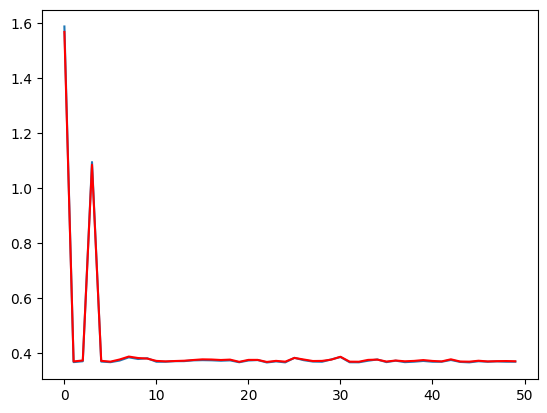

In [254]:
plt.plot(np.arange(0,Epoches),MSETrainList)
plt.plot(np.arange(0,Epoches),MSETestList,c = "red")

In [ ]:
#COMPARASION
'''Sum1 = 0
Sum2 = 0
for i in range(0,len(X_Test)):
    Sum1 += (Fit.predict(np.array([X_Test[i]])) - Y_Test[i])**2
    Sum2 += (Y_Test[i] - np.dot(Array,X_Test[i]) + Intercept)**2



print(Sum1**(1/2) , Sum2**(1/2))

Sum1 = 0
Sum2 = 0
for i in range(0,len(X_Train)):
    Sum1 += (Fit.predict(np.array([X_Train[i]])) - Y_Train[i])**2
    Sum2 += (Y_Train[i] - np.dot(Array,X_Train[i]) + Intercept)**2
print(Sum1**(1/2) , Sum2**(1/2))
'''

'Sum1 = 0\nSum2 = 0\nfor i in range(0,len(X_Test)):\n    Sum1 += (Fit.predict(np.array([X_Test[i]])) - Y_Test[i])**2\n    Sum2 += (Y_Test[i] - np.dot(Array,X_Test[i]) + Intercept)**2\n\n\n\nprint(Sum1**(1/2) , Sum2**(1/2))\n\nSum1 = 0\nSum2 = 0\nfor i in range(0,len(X_Train)):\n    Sum1 += (Fit.predict(np.array([X_Train[i]])) - Y_Train[i])**2\n    Sum2 += (Y_Train[i] - np.dot(Array,X_Train[i]) + Intercept)**2\nprint(Sum1**(1/2) , Sum2**(1/2))\n'